# Praktikum Data Mining: Klasifikasi dengan Naive Bayes & k-Nearest Neighbor (k-NN)
Nama: Auditya Merosya Putri 
NIM: 24343001

## 4.1 Persiapan Lingkungan

In [15]:
import sys, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.naive_bayes import CategoricalNB, GaussianNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris, load_wine, make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams['figure.dpi'] = 150   # grafik lebih tajam
print('Python      :', sys.version.split()[0])
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('scikit-learn:', sklearn.__version__)

Python      : 3.13.9
pandas      : 2.3.3
numpy       : 2.3.5
scikit-learn: 1.7.2


## 4.2 Load dan Eksplorasi Dataset Play Tennis

In [16]:
df = pd.read_csv('play_tennis.csv')
print(df.head())

  Day   Outlook Temperature Humidity    Wind PlayTennis
0  D1     Sunny         Hot     High    Weak         No
1  D2     Sunny         Hot     High  Strong         No
2  D3  Overcast         Hot     High    Weak        Yes
3  D4      Rain        Mild     High    Weak        Yes
4  D5      Rain        Cool   Normal    Weak        Yes


In [17]:
print(df['PlayTennis'].value_counts())

PlayTennis
Yes    9
No     5
Name: count, dtype: int64


## 4.3 Encoding Fitur Kategorikal

In [18]:
fitur = ['Outlook', 'Temperature', 'Humidity', 'Wind']
X = df[fitur].copy()
y = df['PlayTennis'].copy()

enc = OrdinalEncoder()
X_enc = pd.DataFrame(enc.fit_transform(X), columns=fitur)

for col, cats in zip(fitur, enc.categories_):
    print(f'{col}: {dict(zip(cats, range(len(cats))))}')

Outlook: {'Overcast': 0, 'Rain': 1, 'Sunny': 2}
Temperature: {'Cool': 0, 'Hot': 1, 'Mild': 2}
Humidity: {'High': 0, 'Normal': 1}
Wind: {'Strong': 0, 'Weak': 1}


## 4.4 Membangun Model Naive Bayes pada Play Tennis

In [19]:
clf_nb = CategoricalNB()
clf_nb.fit(X_enc, y)

for cls, logp in zip(clf_nb.classes_, clf_nb.class_log_prior_):
    print(f'P({cls}) = {np.exp(logp):.4f}')

P(No) = 0.3571
P(Yes) = 0.6429


## 4.5 Prediksi Data Baru dengan Naive Bayes

In [20]:
data_baru = pd.DataFrame([{
    'Outlook': 'Sunny', 'Temperature': 'Cool',
    'Humidity': 'High', 'Wind': 'Strong'
}])
data_baru_enc = pd.DataFrame(enc.transform(data_baru), columns=fitur)

pred = clf_nb.predict(data_baru_enc)
proba = clf_nb.predict_proba(data_baru_enc)
print('Prediksi:', pred[0])
print('Probabilitas:', {str(c): round(float(p), 4) for c, p in zip(clf_nb.classes_, proba[0])})

Prediksi: No
Probabilitas: {'No': 0.7201, 'Yes': 0.2799}


## 4.6 Naive Bayes pada Dataset Iris (Evaluasi dengan Train/Test Split)

In [21]:
iris = load_iris()
Xi = pd.DataFrame(iris.data, columns=iris.feature_names)
yi = iris.target

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=42, stratify=yi)
print(f'Data latih: {len(Xi_train)} | Data uji: {len(Xi_test)}')

nb = GaussianNB()
nb.fit(Xi_train, yi_train)
nb_pred = nb.predict(Xi_test)

print('Akurasi:', accuracy_score(yi_test, nb_pred))
print(classification_report(yi_test, nb_pred, target_names=iris.target_names, digits=3))

Data latih: 105 | Data uji: 45
Akurasi: 0.9111111111111111
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.824     0.933     0.875        15
   virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45



[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]


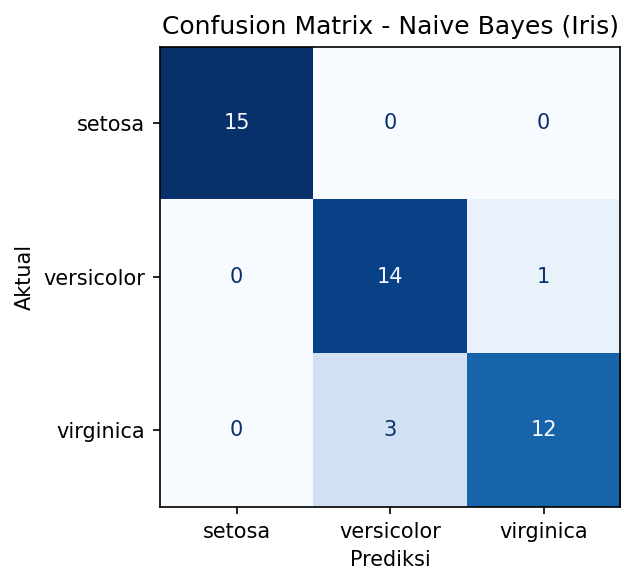

In [22]:
cm_nb = confusion_matrix(yi_test, nb_pred)
print(cm_nb)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_nb, display_labels=iris.target_names).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix - Naive Bayes (Iris)')
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout(); plt.show()

## 4.7 Membangun Model k-NN pada Dataset Iris

In [23]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xi_train, yi_train)
knn_pred = knn.predict(Xi_test)

print('Akurasi:', accuracy_score(yi_test, knn_pred))
print(classification_report(yi_test, knn_pred, target_names=iris.target_names, digits=3))

Akurasi: 0.9777777777777777
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.938     1.000     0.968        15
   virginica      1.000     0.933     0.966        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45



[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]


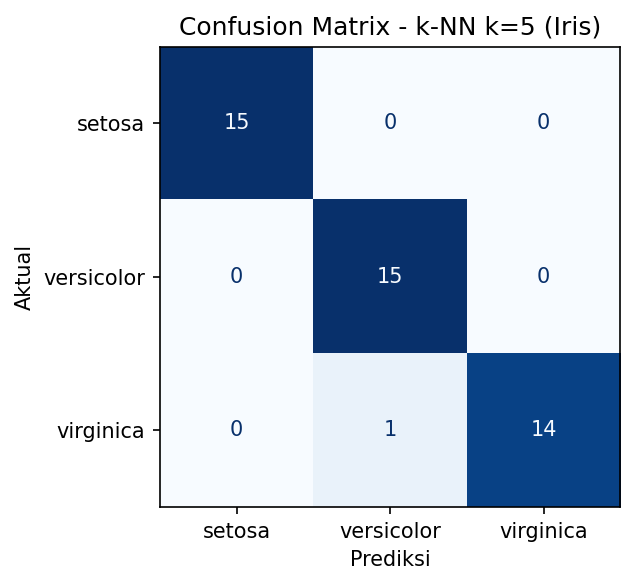

In [24]:
cm_knn = confusion_matrix(yi_test, knn_pred)
print(cm_knn)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_knn, display_labels=iris.target_names).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix - k-NN k=5 (Iris)')
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout(); plt.show()

### Prediksi data bunga baru

In [25]:
bunga_baru = pd.DataFrame([[5.0, 3.4, 1.5, 0.2]], columns=iris.feature_names)
pred_bunga = knn.predict(bunga_baru)
print('Prediksi kelas:', iris.target_names[pred_bunga[0]])

Prediksi kelas: setosa


## 4.8 Eksperimen: Pencarian Nilai k Optimal

In [26]:
k_range = range(1, 21)
k_scores = []
for k in k_range:
    c = KNeighborsClassifier(n_neighbors=k)
    c.fit(Xi_train, yi_train)
    acc = accuracy_score(yi_test, c.predict(Xi_test))
    k_scores.append(acc)
    print(f'k={k}: akurasi = {acc:.4f}')

k=1: akurasi = 0.9333
k=2: akurasi = 0.9111
k=3: akurasi = 0.9556
k=4: akurasi = 0.9556
k=5: akurasi = 0.9778
k=6: akurasi = 0.9556
k=7: akurasi = 0.9556
k=8: akurasi = 0.9333
k=9: akurasi = 0.9556
k=10: akurasi = 0.9556
k=11: akurasi = 0.9333
k=12: akurasi = 0.9333
k=13: akurasi = 0.9333
k=14: akurasi = 0.9333
k=15: akurasi = 0.9556
k=16: akurasi = 0.9556
k=17: akurasi = 0.9556
k=18: akurasi = 0.9556
k=19: akurasi = 0.9556
k=20: akurasi = 0.9333


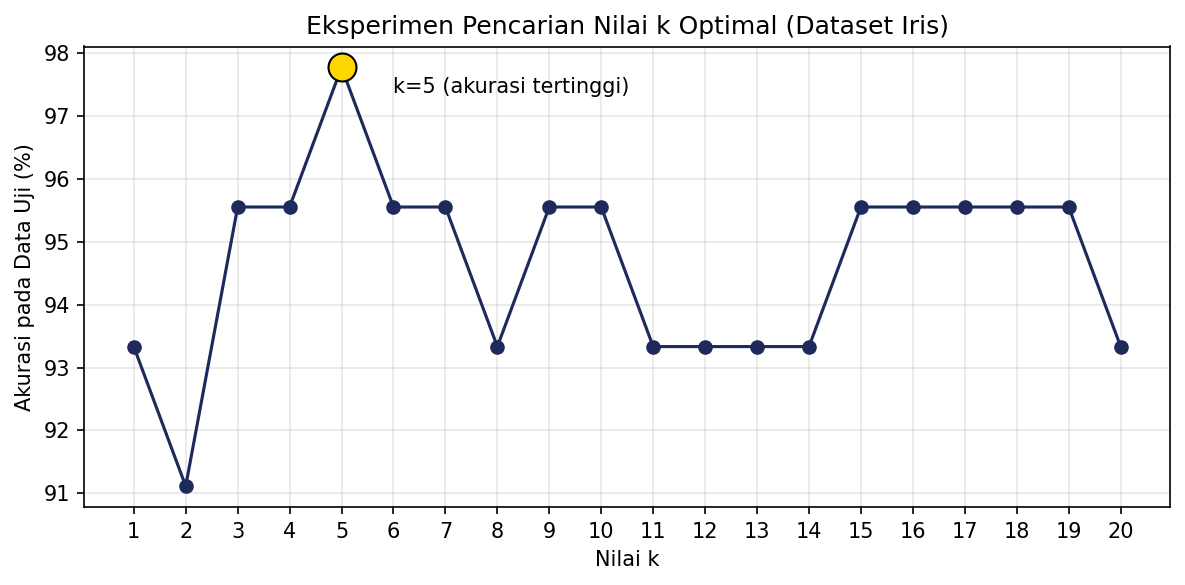

k terbaik: 5 | akurasi: 0.9778


In [27]:
best_k = list(k_range)[int(np.argmax(k_scores))]
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), [s*100 for s in k_scores], marker='o', color='#1f2a5c')
plt.scatter([best_k], [max(k_scores)*100], s=180, color='gold', edgecolor='black', zorder=5)
plt.annotate(f'k={best_k} (akurasi tertinggi)', (best_k, max(k_scores)*100),
             xytext=(best_k+1, max(k_scores)*100-0.4))
plt.xticks(list(k_range)); plt.grid(alpha=.3)
plt.xlabel('Nilai k'); plt.ylabel('Akurasi pada Data Uji (%)')
plt.title('Eksperimen Pencarian Nilai k Optimal (Dataset Iris)')
plt.tight_layout(); plt.show()
print('k terbaik:', best_k, '| akurasi:', round(max(k_scores), 4))

## 4.9 Perbandingan Naive Bayes vs k-NN

Naive Bayes (Gaussian): 0.9111111111111111
k-NN (k=5): 0.9777777777777777


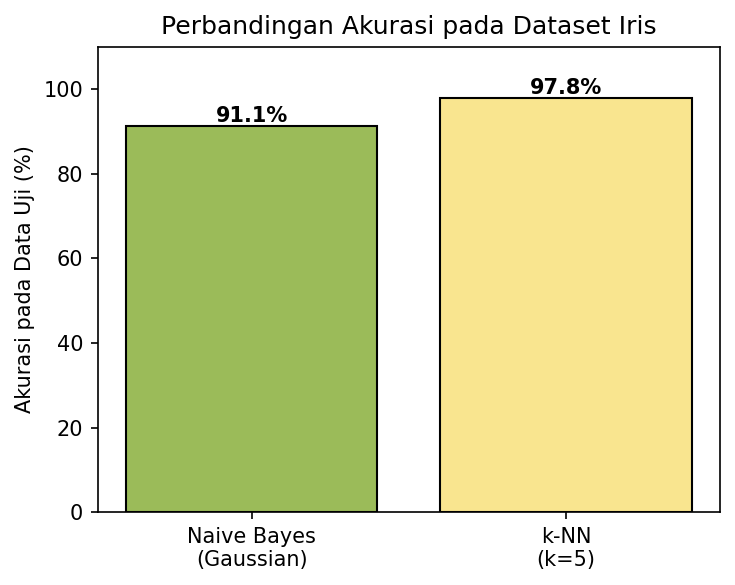

In [28]:
acc_nb  = accuracy_score(yi_test, nb_pred)
acc_knn = accuracy_score(yi_test, knn_pred)
print('Naive Bayes (Gaussian):', acc_nb)
print('k-NN (k=5):', acc_knn)

plt.figure(figsize=(5, 4))
bars = plt.bar(['Naive Bayes\n(Gaussian)', 'k-NN\n(k=5)'], [acc_nb*100, acc_knn*100],
               color=['#9bbb59', '#f9e58f'], edgecolor='black')
for b, v in zip(bars, [acc_nb*100, acc_knn*100]):
    plt.text(b.get_x()+b.get_width()/2, v+1, f'{v:.1f}%', ha='center', fontweight='bold')
plt.ylim(0, 110); plt.ylabel('Akurasi pada Data Uji (%)')
plt.title('Perbandingan Akurasi pada Dataset Iris')
plt.tight_layout(); plt.show()

---
# TUGAS 1: Variasi Varian Naive Bayes


### 1. Ulangi langkah 4.4 dengan OneHotEncoder + BernoulliNB

#### a. Encoding dengan OneHotEncoder

In [29]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import BernoulliNB

ohe = OneHotEncoder(sparse_output=False)
X_ohe = ohe.fit_transform(X)
print('Jumlah kolom one-hot:', X_ohe.shape[1])
print(list(ohe.get_feature_names_out(fitur)))

Jumlah kolom one-hot: 10
['Outlook_Overcast', 'Outlook_Rain', 'Outlook_Sunny', 'Temperature_Cool', 'Temperature_Hot', 'Temperature_Mild', 'Humidity_High', 'Humidity_Normal', 'Wind_Strong', 'Wind_Weak']


#### b. Bangun model BernoulliNB

In [30]:
bnb = BernoulliNB()          # alpha=1.0 (Laplace smoothing), binarize=0.0 (data sudah 0/1)
bnb.fit(X_ohe, y)

for cls, logp in zip(bnb.classes_, bnb.class_log_prior_):
    print(f'P({cls}) = {np.exp(logp):.4f}')

P(No) = 0.3571
P(Yes) = 0.6429


#### c. Prediksi data baru dan bandingkan dengan CategoricalNB

In [31]:
data_baru_ohe = ohe.transform(data_baru)
pred_b = bnb.predict(data_baru_ohe)
proba_b = bnb.predict_proba(data_baru_ohe)
print('CategoricalNB :', pred[0], {str(c): round(float(p), 4) for c, p in zip(clf_nb.classes_, proba[0])})
print('BernoulliNB   :', pred_b[0], {str(c): round(float(p), 4) for c, p in zip(bnb.classes_, proba_b[0])})

CategoricalNB : No {'No': 0.7201, 'Yes': 0.2799}
BernoulliNB   : No {'No': 0.9101, 'Yes': 0.0899}


In [32]:
# Perbandingan pada seluruh 14 data
p_cat = clf_nb.predict(X_enc)
p_ber = bnb.predict(X_ohe)
print('Prediksi sama pada', (p_cat == p_ber).sum(), 'dari', len(p_cat), 'baris')
print('Akurasi CategoricalNB:', round(accuracy_score(y, p_cat), 4))
print('Akurasi BernoulliNB  :', round(accuracy_score(y, p_ber), 4))

Prediksi sama pada 14 dari 14 baris
Akurasi CategoricalNB: 0.9286
Akurasi BernoulliNB  : 0.9286


### 2. Tambah 3 baris data baru, amati prior P(Yes) dan P(No)

#### a. Tambah 3 baris data baru

In [33]:
tambahan = pd.DataFrame([
    ('D15', 'Sunny', 'Cool', 'High', 'Strong', 'No'),
    ('D16', 'Overcast', 'Hot', 'Normal', 'Strong', 'Yes'),
    ('D17', 'Rain', 'Hot', 'High', 'Weak', 'No')],
    columns=df.columns)
df2 = pd.concat([df, tambahan], ignore_index=True)
df2.to_csv('play_tennis_modifikasi.csv', index=False)
print(df2)
print()
print(df2['PlayTennis'].value_counts())

    Day   Outlook Temperature Humidity    Wind PlayTennis
0    D1     Sunny         Hot     High    Weak         No
1    D2     Sunny         Hot     High  Strong         No
2    D3  Overcast         Hot     High    Weak        Yes
3    D4      Rain        Mild     High    Weak        Yes
4    D5      Rain        Cool   Normal    Weak        Yes
5    D6      Rain        Cool   Normal  Strong         No
6    D7  Overcast        Cool   Normal  Strong        Yes
7    D8     Sunny        Mild     High    Weak         No
8    D9     Sunny        Cool   Normal    Weak        Yes
9   D10      Rain        Mild   Normal    Weak        Yes
10  D11     Sunny        Mild   Normal  Strong        Yes
11  D12  Overcast        Mild     High  Strong        Yes
12  D13  Overcast         Hot   Normal    Weak        Yes
13  D14      Rain        Mild     High  Strong         No
14  D15     Sunny        Cool     High  Strong         No
15  D16  Overcast         Hot   Normal  Strong        Yes
16  D17      R

#### b. Latih ulang model dan bandingkan prior

In [34]:
enc2 = OrdinalEncoder()
X2_enc = pd.DataFrame(enc2.fit_transform(df2[fitur]), columns=fitur)
clf_nb2 = CategoricalNB().fit(X2_enc, df2['PlayTennis'])

print('Prior sebelum (14 data) vs sesudah (17 data):')
for cls, l1, l2 in zip(clf_nb.classes_, clf_nb.class_log_prior_, clf_nb2.class_log_prior_):
    print(f'P({cls}): {np.exp(l1):.4f} -> {np.exp(l2):.4f}')

Prior sebelum (14 data) vs sesudah (17 data):
P(No): 0.3571 -> 0.4118
P(Yes): 0.6429 -> 0.5882


#### c. Prediksi data baru sebelum vs sesudah penambahan data

In [35]:
baru_enc2 = pd.DataFrame(enc2.transform(data_baru), columns=fitur)
proba2 = clf_nb2.predict_proba(baru_enc2)
print('Prediksi sebelum:', pred[0], {str(c): round(float(p), 4) for c, p in zip(clf_nb.classes_, proba[0])})
print('Prediksi sesudah:', clf_nb2.predict(baru_enc2)[0], {str(c): round(float(p), 4) for c, p in zip(clf_nb2.classes_, proba2[0])})

Prediksi sebelum: No {'No': 0.7201, 'Yes': 0.2799}
Prediksi sesudah: No {'No': 0.8214, 'Yes': 0.1786}


---
# TUGAS 2: Evaluasi Mendalam k-NN
Bandingkan metrik jarak Manhattan dengan Euclidean, lalu uji pengaruh normalisasi fitur (StandardScaler) pada Iris.

### 1. Ulangi langkah 4.7 dengan metrik Manhattan

In [36]:
knn_euc = KNeighborsClassifier(n_neighbors=5)                       # default: Euclidean (minkowski, p=2)
knn_man = KNeighborsClassifier(n_neighbors=5, metric='manhattan')
knn_euc.fit(Xi_train, yi_train)
knn_man.fit(Xi_train, yi_train)

p_euc = knn_euc.predict(Xi_test)
p_man = knn_man.predict(Xi_test)
print('Akurasi k-NN Euclidean:', round(accuracy_score(yi_test, p_euc), 4), f'({(p_euc == yi_test).sum()}/{len(yi_test)} benar)')
print('Akurasi k-NN Manhattan:', round(accuracy_score(yi_test, p_man), 4), f'({(p_man == yi_test).sum()}/{len(yi_test)} benar)')

Akurasi k-NN Euclidean: 0.9778 (44/45 benar)
Akurasi k-NN Manhattan: 0.9333 (42/45 benar)


In [37]:
print('Confusion matrix Euclidean:')
print(confusion_matrix(yi_test, p_euc))
print('Confusion matrix Manhattan:')
print(confusion_matrix(yi_test, p_man))
print()
print(classification_report(yi_test, p_man, target_names=iris.target_names, digits=3))

Confusion matrix Euclidean:
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]
Confusion matrix Manhattan:
[[15  0  0]
 [ 0 15  0]
 [ 0  3 12]]

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.833     1.000     0.909        15
   virginica      1.000     0.800     0.889        15

    accuracy                          0.933        45
   macro avg      0.944     0.933     0.933        45
weighted avg      0.944     0.933     0.933        45



### 2. Normalisasi fitur Iris dengan StandardScaler

#### a. Periksa rentang nilai fitur (data latih)

In [38]:
from sklearn.preprocessing import StandardScaler

print(Xi_train.describe().loc[['min', 'max', 'mean', 'std']].round(2))

      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
min                4.30              2.00               1.10              0.10
max                7.90              4.40               6.90              2.50
mean               5.87              3.06               3.78              1.21
std                0.86              0.46               1.78              0.78


#### b. Latih k-NN sebelum vs sesudah scaling

In [39]:
scaler = StandardScaler()
Xi_train_s = scaler.fit_transform(Xi_train)   # fit hanya pada data latih (hindari data leakage)
Xi_test_s = scaler.transform(Xi_test)

for metrik in ['euclidean', 'manhattan']:
    m = KNeighborsClassifier(n_neighbors=5, metric=metrik)
    a_raw = accuracy_score(yi_test, m.fit(Xi_train, yi_train).predict(Xi_test))
    a_std = accuracy_score(yi_test, m.fit(Xi_train_s, yi_train).predict(Xi_test_s))
    print(f'{metrik:10s} | tanpa scaling: {a_raw:.4f} | dengan StandardScaler: {a_std:.4f}')

p_s = KNeighborsClassifier(n_neighbors=5).fit(Xi_train_s, yi_train).predict(Xi_test_s)
print('Confusion matrix (Euclidean + StandardScaler):')
print(confusion_matrix(yi_test, p_s))

euclidean  | tanpa scaling: 0.9778 | dengan StandardScaler: 0.9111
manhattan  | tanpa scaling: 0.9333 | dengan StandardScaler: 0.9111
Confusion matrix (Euclidean + StandardScaler):
[[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]


#### c. Pengaruh scaling pada berbagai nilai k (Euclidean)

In [40]:
print(' k | tanpa scaling | StandardScaler')
sel = []
for k in range(1, 21):
    a1 = accuracy_score(yi_test, KNeighborsClassifier(n_neighbors=k).fit(Xi_train, yi_train).predict(Xi_test))
    a2 = accuracy_score(yi_test, KNeighborsClassifier(n_neighbors=k).fit(Xi_train_s, yi_train).predict(Xi_test_s))
    sel.append((k, a1, a2))
    print(f'{k:2d} |    {a1:.4f}     |    {a2:.4f}')
print('Rata-rata k=1..20:', round(np.mean([s[1] for s in sel]), 4), 'vs', round(np.mean([s[2] for s in sel]), 4))

 k | tanpa scaling | StandardScaler
 1 |    0.9333     |    0.9333
 2 |    0.9111     |    0.8889
 3 |    0.9556     |    0.9111
 4 |    0.9556     |    0.9111
 5 |    0.9778     |    0.9111
 6 |    0.9556     |    0.9111
 7 |    0.9556     |    0.9333
 8 |    0.9333     |    0.9111
 9 |    0.9556     |    0.9556
10 |    0.9556     |    0.9333
11 |    0.9333     |    0.9556
12 |    0.9333     |    0.9556
13 |    0.9333     |    0.9333
14 |    0.9333     |    0.9556
15 |    0.9556     |    0.9333
16 |    0.9556     |    0.9111
17 |    0.9556     |    0.9111
18 |    0.9556     |    0.9111
19 |    0.9556     |    0.9111
20 |    0.9333     |    0.8889
Rata-rata k=1..20: 0.9467 vs 0.9233


---
# TUGAS 3: Dataset Baru (Wine, UCI Machine Learning Repository)
Dataset kimia anggur: **178 baris**, 13 fitur numerik, target kategorikal 3 kelas (cultivar). Dataset tersedia di scikit-learn (sumber asli: UCI Machine Learning Repository), jadi memenuhi syarat minimal 50 baris dan target kategorikal.

### 1. Cari dataset tabular lain: load dan eksplorasi

In [41]:
from sklearn.datasets import load_wine

wine = load_wine()
Xw = pd.DataFrame(wine.data, columns=wine.feature_names)
yw = wine.target
print('Jumlah baris :', Xw.shape[0])
print('Jumlah fitur :', Xw.shape[1])
print('Kelas target :', [str(n) for n in wine.target_names])
print('Distribusi   :', {str(n): int(v) for n, v in zip(wine.target_names, np.bincount(yw))})
print('Nilai kosong :', int(Xw.isnull().sum().sum()))
print(Xw[['alcohol', 'malic_acid', 'magnesium', 'flavanoids', 'color_intensity', 'proline']].head())

Jumlah baris : 178
Jumlah fitur : 13
Kelas target : ['class_0', 'class_1', 'class_2']
Distribusi   : {'class_0': 59, 'class_1': 71, 'class_2': 48}
Nilai kosong : 0
   alcohol  malic_acid  magnesium  flavanoids  color_intensity  proline
0    14.23        1.71      127.0        3.06             5.64   1065.0
1    13.20        1.78      100.0        2.76             4.38   1050.0
2    13.16        2.36      101.0        3.24             5.68   1185.0
3    14.37        1.95      113.0        3.49             7.80   1480.0
4    13.24        2.59      118.0        2.69             4.32    735.0


In [42]:
print(Xw.describe().loc[['min', 'max', 'std']].T.round(2))

                                 min      max     std
alcohol                        11.03    14.83    0.81
malic_acid                      0.74     5.80    1.12
ash                             1.36     3.23    0.27
alcalinity_of_ash              10.60    30.00    3.34
magnesium                      70.00   162.00   14.28
total_phenols                   0.98     3.88    0.63
flavanoids                      0.34     5.08    1.00
nonflavanoid_phenols            0.13     0.66    0.12
proanthocyanins                 0.41     3.58    0.57
color_intensity                 1.28    13.00    2.32
hue                             0.48     1.71    0.23
od280/od315_of_diluted_wines    1.27     4.00    0.71
proline                       278.00  1680.00  314.91


### 2. Terapkan Naive Bayes dan k-NN (split data latih/uji, akurasi, confusion matrix)

#### a. Split data latih/uji

In [43]:
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    Xw, yw, test_size=0.3, random_state=42, stratify=yw)
print(f'Data latih: {len(Xw_train)} | Data uji: {len(Xw_test)}')

Data latih: 124 | Data uji: 54


#### b. Bangun model dan hitung akurasi

In [44]:
# Naive Bayes (Gaussian)
nb_w = GaussianNB().fit(Xw_train, yw_train)
nb_w_pred = nb_w.predict(Xw_test)

# k-NN (k=5, tanpa scaling)
knn_w = KNeighborsClassifier(n_neighbors=5).fit(Xw_train, yw_train)
knn_w_pred = knn_w.predict(Xw_test)

print('=== Naive Bayes (Gaussian) ===')
print('Akurasi:', round(accuracy_score(yw_test, nb_w_pred), 4))
print(classification_report(yw_test, nb_w_pred, target_names=wine.target_names, digits=3))
print('=== k-NN (k=5) ===')
print('Akurasi:', round(accuracy_score(yw_test, knn_w_pred), 4))
print(classification_report(yw_test, knn_w_pred, target_names=wine.target_names, digits=3))

=== Naive Bayes (Gaussian) ===
Akurasi: 1.0
              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        18
     class_1      1.000     1.000     1.000        21
     class_2      1.000     1.000     1.000        15

    accuracy                          1.000        54
   macro avg      1.000     1.000     1.000        54
weighted avg      1.000     1.000     1.000        54

=== k-NN (k=5) ===
Akurasi: 0.7222
              precision    recall  f1-score   support

     class_0      0.889     0.889     0.889        18
     class_1      0.778     0.667     0.718        21
     class_2      0.500     0.600     0.545        15

    accuracy                          0.722        54
   macro avg      0.722     0.719     0.717        54
weighted avg      0.738     0.722     0.727        54



#### c. Confusion matrix

Naive Bayes (Gaussian)
[[18  0  0]
 [ 0 21  0]
 [ 0  0 15]]
k-NN (k=5)
[[16  0  2]
 [ 0 14  7]
 [ 2  4  9]]


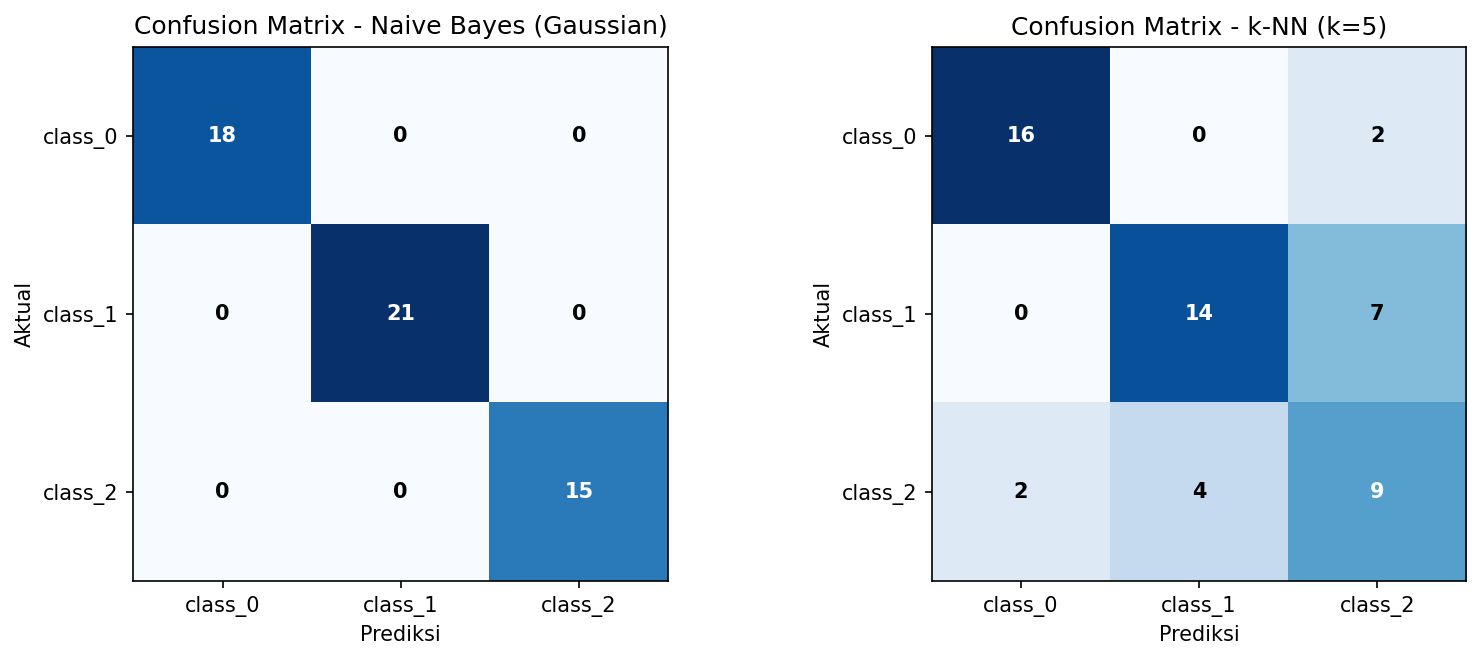

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pr, judul in zip(axes, [nb_w_pred, knn_w_pred], ['Naive Bayes (Gaussian)', 'k-NN (k=5)']):
    cm = confusion_matrix(yw_test, pr)
    print(judul)
    print(cm)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(wine.target_names); ax.set_yticklabels(wine.target_names)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
    ax.set_title(f'Confusion Matrix - {judul}')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black', fontweight='bold')
plt.tight_layout()
plt.savefig('tugas3_confusion_matrix.png', dpi=150)
plt.show()

### 3. Interpretasi: algoritma mana yang lebih unggul dan mengapa?

In [46]:
# Pembanding tambahan: k-NN setelah StandardScaler (untuk mendukung interpretasi)
sc_w = StandardScaler().fit(Xw_train)
knn_ws = KNeighborsClassifier(n_neighbors=5).fit(sc_w.transform(Xw_train), yw_train)
knn_ws_pred = knn_ws.predict(sc_w.transform(Xw_test))

print('Akurasi k-NN tanpa scaling       :', round(accuracy_score(yw_test, knn_w_pred), 4))
print('Akurasi k-NN dengan StandardScaler:', round(accuracy_score(yw_test, knn_ws_pred), 4))
print('Akurasi Naive Bayes               :', round(accuracy_score(yw_test, nb_w_pred), 4))
print(confusion_matrix(yw_test, knn_ws_pred))

Akurasi k-NN tanpa scaling       : 0.7222
Akurasi k-NN dengan StandardScaler: 0.9444
Akurasi Naive Bayes               : 1.0
[[18  0  0]
 [ 0 18  3]
 [ 0  0 15]]


---
# TUGAS 4: Analisis Kritis
Analisis grafik akurasi terhadap k, serta perbandingan karakteristik komputasi Naive Bayes (eager learning) dan k-NN (lazy learning).

### 1. Mengapa grafik akurasi terhadap k tidak monoton (naik-turun)?

#### a. Jumlah kesalahan pada data uji untuk setiap k

In [47]:
# 1 data uji = 1/45 = 2,22 poin persen
print(' k | benar | salah | akurasi')
for k, s in zip(k_range, k_scores):
    benar = round(s * len(yi_test))
    print(f'{k:2d} |  {benar:2d}   |  {len(yi_test) - benar:2d}   | {s:.4f}')

 k | benar | salah | akurasi
 1 |  42   |   3   | 0.9333
 2 |  41   |   4   | 0.9111
 3 |  43   |   2   | 0.9556
 4 |  43   |   2   | 0.9556
 5 |  44   |   1   | 0.9778
 6 |  43   |   2   | 0.9556
 7 |  43   |   2   | 0.9556
 8 |  42   |   3   | 0.9333
 9 |  43   |   2   | 0.9556
10 |  43   |   2   | 0.9556
11 |  42   |   3   | 0.9333
12 |  42   |   3   | 0.9333
13 |  42   |   3   | 0.9333
14 |  42   |   3   | 0.9333
15 |  43   |   2   | 0.9556
16 |  43   |   2   | 0.9556
17 |  43   |   2   | 0.9556
18 |  43   |   2   | 0.9556
19 |  43   |   2   | 0.9556
20 |  42   |   3   | 0.9333


#### b. Pembanding: Cross-Validation 5-fold pada data latih

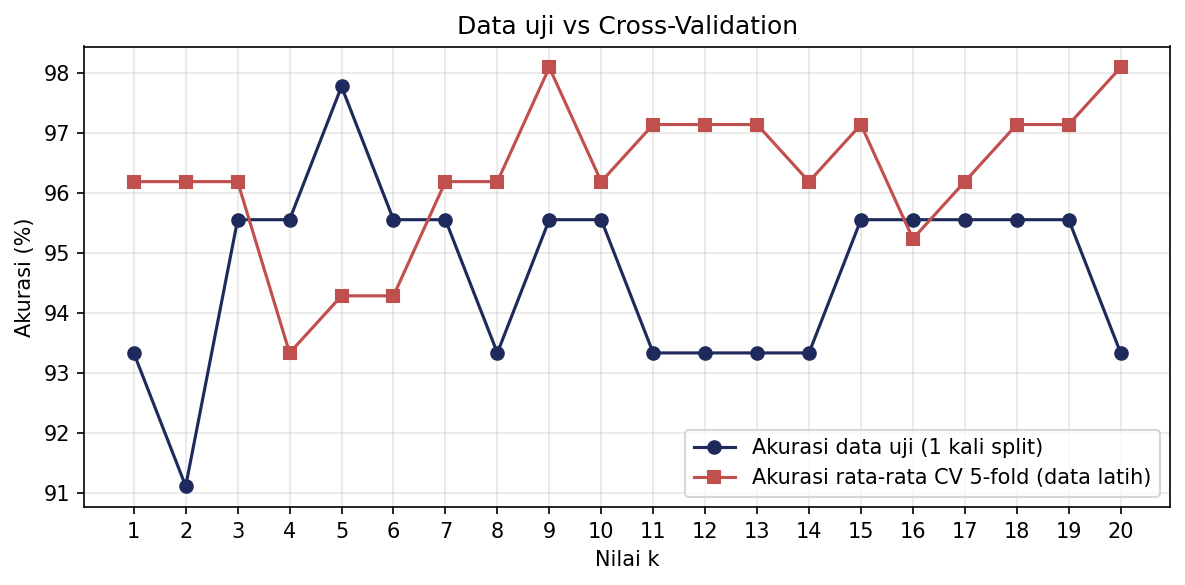

Akurasi CV per k : [0.9619, 0.9619, 0.9619, 0.9333, 0.9429, 0.9429, 0.9619, 0.9619, 0.981, 0.9619, 0.9714, 0.9714, 0.9714, 0.9619, 0.9714, 0.9524, 0.9619, 0.9714, 0.9714, 0.981]
Rentang akurasi data uji : 91.11 - 97.78 %
Rentang akurasi CV 5-fold: 93.33 - 98.1 %
k terbaik menurut CV     : 9 | akurasi CV: 0.981


In [48]:
# Pembanding: akurasi cross-validation 5-fold pada data latih (lebih stabil daripada 1 kali split)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), Xi_train, yi_train, cv=5).mean() for k in k_range]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(k_range), [s*100 for s in k_scores], marker='o', label='Akurasi data uji (1 kali split)', color='#1f2a5c')
ax.plot(list(k_range), [s*100 for s in cv_scores], marker='s', label='Akurasi rata-rata CV 5-fold (data latih)', color='#c0504d')
ax.set_xticks(list(k_range)); ax.grid(alpha=.3); ax.legend()
ax.set_xlabel('Nilai k'); ax.set_ylabel('Akurasi (%)'); ax.set_title('Data uji vs Cross-Validation')
plt.tight_layout(); plt.show()
print('Akurasi CV per k :', [round(float(c), 4) for c in cv_scores])
print('Rentang akurasi data uji :', round(min(k_scores)*100,2), '-', round(max(k_scores)*100,2), '%')
print('Rentang akurasi CV 5-fold:', round(min(cv_scores)*100,2), '-', round(max(cv_scores)*100,2), '%')
print('k terbaik menurut CV     :', list(k_range)[int(np.argmax(cv_scores))], '| akurasi CV:', round(max(cv_scores), 4))

### 2. Naive Bayes (eager learning) vs k-NN (lazy learning) pada dataset berukuran besar

#### a. Ukur waktu pelatihan dan prediksi pada data sintetis

In [49]:
import time
from sklearn.datasets import make_classification

# Dataset sintetis berukuran besar (20 fitur numerik, 3 kelas); waktu bergantung pada perangkat
ukuran = [10_000, 50_000, 100_000, 200_000, 500_000]
n_uji = 2_000
hasil_waktu = []
for n in ukuran:
    Xs, ys = make_classification(n_samples=n + n_uji, n_features=20, n_informative=10,
                                 n_classes=3, random_state=42)
    Xl, yl, Xu = Xs[:n], ys[:n], Xs[n:]
    # Naive Bayes
    t0 = time.perf_counter(); g = GaussianNB().fit(Xl, yl); t_fit_nb = time.perf_counter() - t0
    t0 = time.perf_counter(); g.predict(Xu); t_pred_nb = time.perf_counter() - t0
    # k-NN
    t0 = time.perf_counter(); kk = KNeighborsClassifier(n_neighbors=5).fit(Xl, yl); t_fit_knn = time.perf_counter() - t0
    t0 = time.perf_counter(); kk.predict(Xu); t_pred_knn = time.perf_counter() - t0
    hasil_waktu.append((n, t_fit_nb, t_pred_nb, t_fit_knn, t_pred_knn))
    print(f'n={n:>7,} | NB latih {t_fit_nb:.4f}s  prediksi {t_pred_nb:.4f}s | k-NN latih {t_fit_knn:.4f}s  prediksi {t_pred_knn:.4f}s')

n= 10,000 | NB latih 0.0062s  prediksi 0.0014s | k-NN latih 0.0012s  prediksi 2.0827s
n= 50,000 | NB latih 0.0279s  prediksi 0.0013s | k-NN latih 0.0052s  prediksi 0.1094s
n=100,000 | NB latih 0.0514s  prediksi 0.0013s | k-NN latih 0.0088s  prediksi 0.2270s
n=200,000 | NB latih 0.1074s  prediksi 0.0014s | k-NN latih 0.0210s  prediksi 0.4011s
n=500,000 | NB latih 0.2368s  prediksi 0.0010s | k-NN latih 0.0503s  prediksi 1.0119s


#### b. Ukuran model dan grafik perbandingan waktu

Naive Bayes menyimpan 123 parameter (rata-rata, varians, prior) ~ 0.96 KB
k-NN menyimpan seluruh data latih: 500000 x 20 ~ 80.0 MB


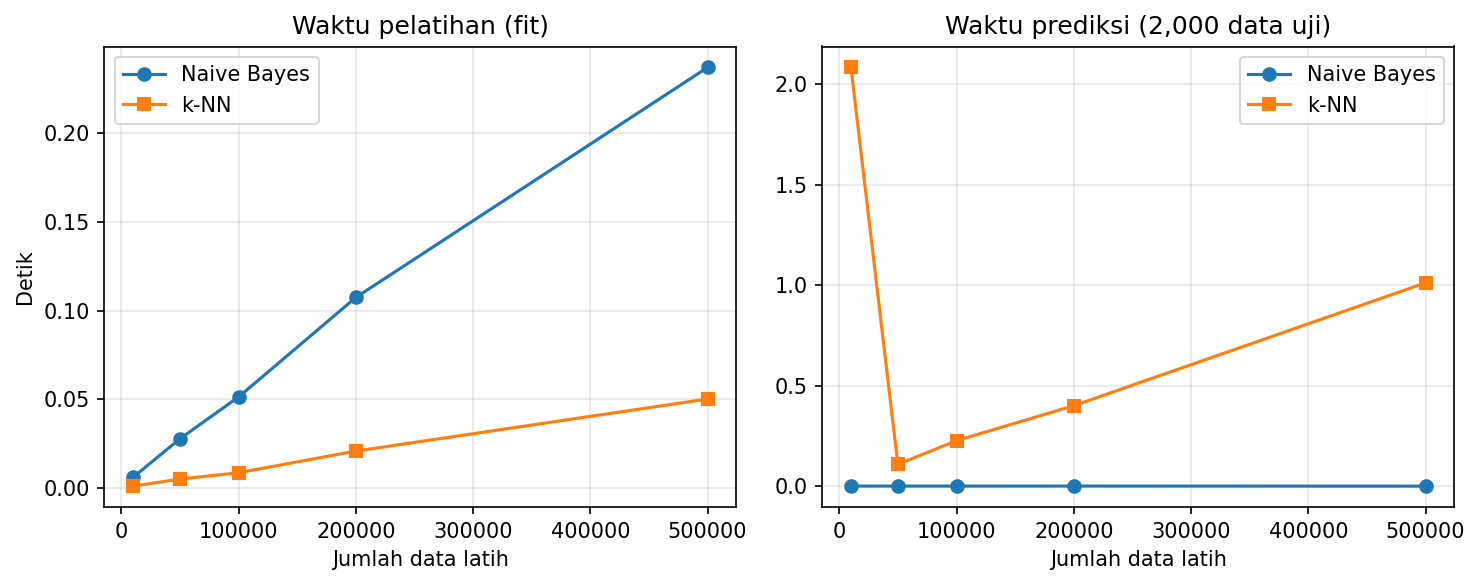

In [50]:
# Ukuran "model" yang harus disimpan untuk prediksi (n = 500.000)
n_param_nb = g.theta_.size + g.var_.size + g.class_prior_.size
mb_knn = Xl.nbytes / 1e6
print('Naive Bayes menyimpan', n_param_nb, 'parameter (rata-rata, varians, prior) ~', round(n_param_nb * 8 / 1024, 2), 'KB')
print('k-NN menyimpan seluruh data latih:', Xl.shape[0], 'x', Xl.shape[1], '~', round(mb_knn, 1), 'MB')

ns = [h[0] for h in hasil_waktu]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ns, [h[1] for h in hasil_waktu], marker='o', label='Naive Bayes')
ax[0].plot(ns, [h[3] for h in hasil_waktu], marker='s', label='k-NN')
ax[0].set_title('Waktu pelatihan (fit)'); ax[0].set_xlabel('Jumlah data latih'); ax[0].set_ylabel('Detik')
ax[1].plot(ns, [h[2] for h in hasil_waktu], marker='o', label='Naive Bayes')
ax[1].plot(ns, [h[4] for h in hasil_waktu], marker='s', label='k-NN')
ax[1].set_title(f'Waktu prediksi ({n_uji:,} data uji)'); ax[1].set_xlabel('Jumlah data latih')
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig('tugas4_waktu_komputasi.png', dpi=150)
plt.show()